In [1]:
import pandas as pd
import numpy as np

# Task 0
Data extraction: get the data from 3 tables & combine it into single `.csv` file.
After that read this file using pandas to create Dataframe.
So it will be all joined data in 1 dataframe. Quick check - should be 74818 rows in it.

In [2]:
# write your code here
import sqlite3
from contextlib import closing
from pathlib import Path


project_root = Path.cwd()
if not (project_root / "db.sqlite3").exists():
    project_root = project_root.parent

database_path = project_root / "db.sqlite3"
csv_path = project_root / "restaurant_data.csv"

query = """
SELECT
    order_item.id AS "Order Item ID",
    restaurant_order.id AS "Order ID",
    restaurant_order.datetime AS "Order Datetime",
    product.id AS "Product ID",
    product.name AS "Product Name",
    product.price AS "Product Price",
    order_item.quantity AS "Quantity"
FROM restaurant_orderitem AS order_item
JOIN restaurant_order AS restaurant_order
    ON restaurant_order.id = order_item.order_id
JOIN restaurant_product AS product
    ON product.id = order_item.product_id
"""

with closing(sqlite3.connect(database_path)) as connection:
    cursor = connection.execute(query)
    joined_data = pd.DataFrame(
        cursor.fetchall(),
        columns=[column[0] for column in cursor.description],
    )

joined_data.to_csv(csv_path, index=False)
df = pd.read_csv(csv_path, parse_dates=["Order Datetime"])
assert len(df) == 74818
df.head()


,Order Item ID,Order ID,Order Datetime,Product ID,Product Name,Product Price,Quantity
0,1,1,2019-08-03 20:25:00,6,Plain Papadum,0.80,2
1,2,1,2019-08-03 20:25:00,240,King Prawn Balti,12.95,1
2,3,1,2019-08-03 20:25:00,19,Garlic Naan,2.95,1
3,4,1,2019-08-03 20:25:00,36,Mushroom Rice,3.95,1
4,5,1,2019-08-03 20:25:00,111,Paneer Tikka Masala,8.95,1


# Task 1
Get Top 10 most popular products in restaurant sold by Quantity.
Count how many times each product was sold and create a pie chart with percentage of popularity (by quantity) for top 10 of them.

Example:

![pie chart](../demo/pie.png)

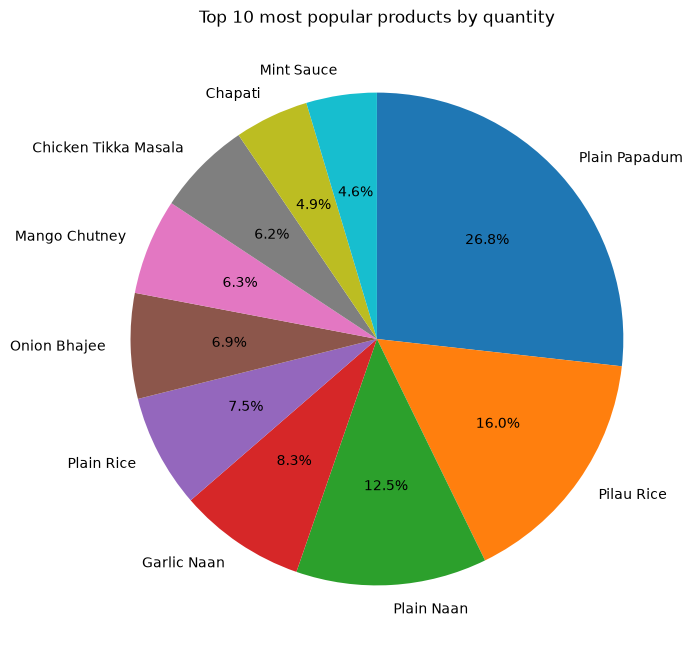

In [4]:
# write your code here
from matplotlib import pyplot as plt
top_products = (
    df.groupby("Product Name")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)
fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(
    top_products,
    labels=top_products.index,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
)
ax.set_title("Top 10 most popular products by quantity")
plt.show()

# Task 2
Calculate `Item Price` (Product Price * Quantity) for each Order Item in dataframe.
And Make the same Top 10 pie chart, but this time by `Item Price`. So this chart should describe not the most popular products by quantity, but which products (top 10) make the most money for restaurant. It should be also with percentage.

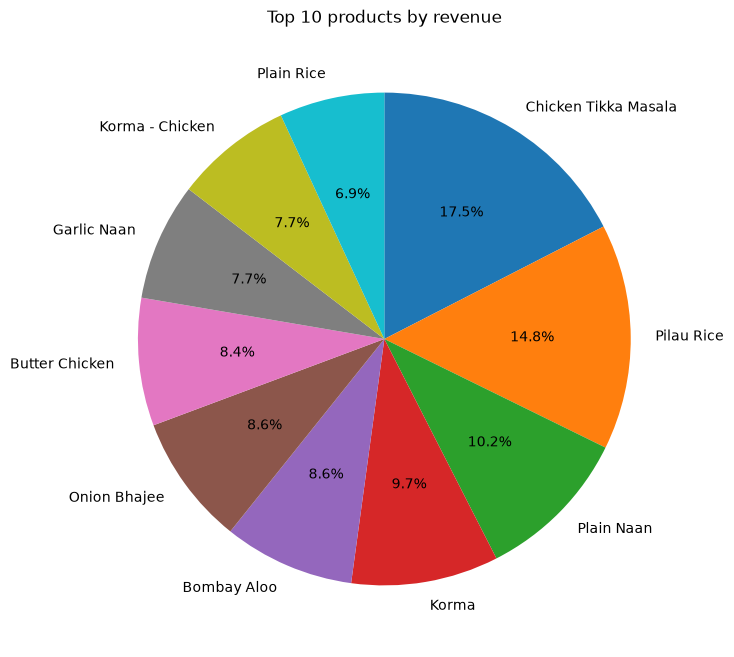

In [7]:
# write your code here
df["Item Price"] = df["Product Price"] * df["Quantity"]
top_products_by_money = (
    df.groupby("Product Name")["Item Price"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)
fig, ax = plt.subplots(figsize=(8, 8))
ax.pie(
    top_products_by_money,
    labels=top_products_by_money.index,
    autopct="%1.1f%%",
    startangle=90,
    counterclock=False,
)
ax.set_title("Top 10 products by revenue")
plt.show()

# Task 3
Calculate `Order Hour` based on `Order Datetime`, which will tell about the specific our the order was created (from 0 to 23). Using `Order Hour` create a bar chart, which will tell the total restaurant income based on the hour order was created. So on x-axis - it will be values from 0 to 23 (hours), on y-axis - it will be the total sum of order prices, which were sold on that hour.

Example:

![bar chart](../demo/bar.png)

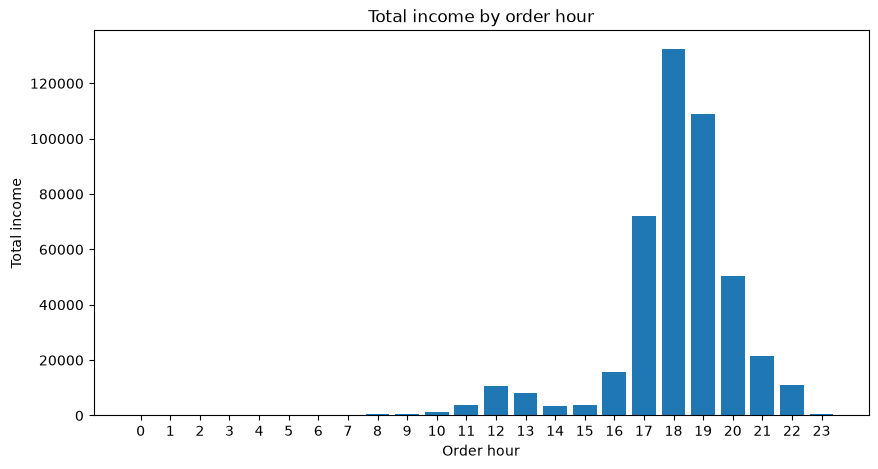

In [9]:
# write your code here
df["Order Hour"] = df["Order Datetime"].dt.hour
income_by_hour = (
    df.groupby("Order Hour")["Item Price"]
    .sum()
    .reindex(range(24), fill_value=0)
)
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(income_by_hour.index, income_by_hour.values)
ax.set_xticks(range(24))
ax.set_xlabel("Order hour")
ax.set_ylabel("Total income")
ax.set_title("Total income by order hour")
plt.show()

# Task 4
Make similar bar chart, but right now with `Order Day Of The Week` (from Monday to Sunday), and also analyze total restaurant income by each day of the week.

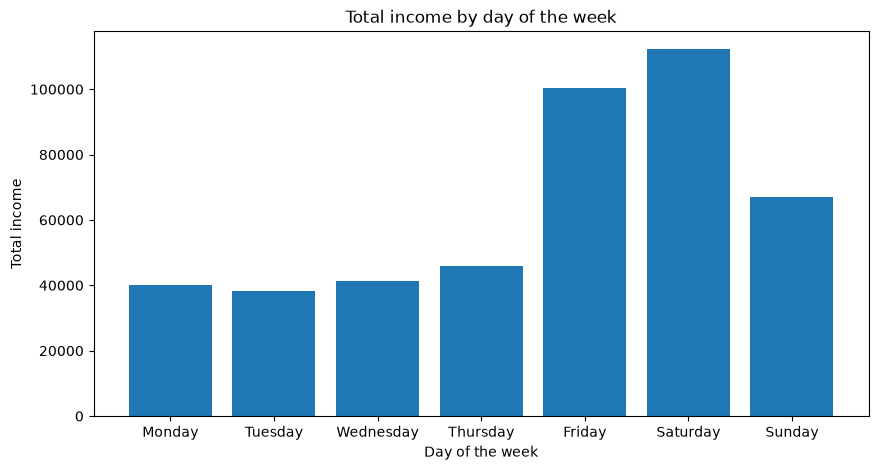

Order Day Of The Week
Monday        8.989448
Tuesday       8.570930
Wednesday     9.267592
Thursday     10.340563
Friday       22.545162
Saturday     25.208296
Sunday       15.078008
Name: Item Price, dtype: float64

In [14]:
# write your code here
df["Order Day Of The Week"] = df["Order Datetime"].dt.day_name()

days_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday",
]

income_by_day = (
    df.groupby("Order Day Of The Week")["Item Price"]
    .sum()
    .reindex(days_order, fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(income_by_day.index, income_by_day.values)
ax.set_xlabel("Day of the week")
ax.set_ylabel("Total income")
ax.set_title("Total income by day of the week")
plt.show()

income_share = (income_by_day / income_by_day.sum() * 100)
income_share